In [1]:
# ********************TASK-2 SALES DATA ANALYSIS *******************

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

from pathlib import Path

CLEANED_PATH = Path("../data/cleaned")
CLEANED_PATH.mkdir(parents=True, exist_ok=True)

REPORT_PATH = Path("../outputs/reports")
REPORT_PATH.mkdir(parents=True, exist_ok=True)

DATA_DIR = "../data/cleaned"
OUTPUT_DIR = "../outputs/reports"

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
customers = pd.read_csv(f"{DATA_DIR}/customers.csv")
orders = pd.read_csv(f"{DATA_DIR}/orders.csv")
order_items = pd.read_csv(f"{DATA_DIR}/order_items.csv")
payments = pd.read_csv(f"{DATA_DIR}/payments.csv")
products = pd.read_csv(f"{DATA_DIR}/products.csv")
sellers = pd.read_csv(f"{DATA_DIR}/sellers.csv")
reviews = pd.read_csv(f"{DATA_DIR}/reviews.csv")
geolocation = pd.read_csv(f"{DATA_DIR}/geolocation.csv")
category_translation = pd.read_csv(
    f"{DATA_DIR}/category_translation.csv"
)

In [4]:
print("Order Status Distribution")

display(
    orders["order_status"]
    .value_counts()
    .reset_index()
    .rename(columns={
        "index": "Order Status",
        "order_status": "Total Orders"
    })
)

Order Status Distribution


,Total Orders,count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [5]:
print("Orders Dataset:")
display(orders.head())

print("Order Items Dataset:")
display(order_items.head())

print("Products Dataset:")
display(products.head())

Orders Dataset:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


Order Items Dataset:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


Products Dataset:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_name_lenght_missing,product_description_lenght_missing,product_photos_qty_missing,product_weight_g_missing,product_length_cm_missing,product_height_cm_missing,product_width_cm_missing
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0,0,0,0,0,0,0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0,0,0,0,0,0,0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0,0,0,0,0,0,0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0,0,0,0,0,0,0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0,0,0,0,0,0,0


In [6]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Total Delivered Orders:", len(delivered_orders))

Total Delivered Orders: 96478


In [7]:
sales_data = order_items.merge(
    delivered_orders,
    on="order_id",
    how="inner"
)

print("Sales data shape:", sales_data.shape)

display(sales_data.head())

Sales data shape: (110197, 14)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17


In [8]:
sales_data = sales_data.merge(
    products,
    on="product_id",
    how="left"
)

print("Product information merged successfully!")

display(sales_data.head())

Product information merged successfully!


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,product_length_cm,product_height_cm,product_width_cm,product_name_lenght_missing,product_description_lenght_missing,product_photos_qty_missing,product_weight_g_missing,product_length_cm_missing,product_height_cm_missing,product_width_cm_missing
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,28.0,9.0,14.0,0,0,0,0,0,0,0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,50.0,30.0,40.0,0,0,0,0,0,0,0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,33.0,13.0,33.0,0,0,0,0,0,0,0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,16.0,10.0,15.0,0,0,0,0,0,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,35.0,40.0,30.0,0,0,0,0,0,0,0


In [9]:
sales_data = sales_data.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

sales_data["product_category_name_english"] = (
    sales_data["product_category_name_english"]
    .fillna("Unknown")
)

print("Category translation completed!")

display(
    sales_data[
        ["order_id", "product_id",
         "product_category_name_english",
         "price", "freight_value"]
    ].head()
)

Category translation completed!


,order_id,product_id,product_category_name_english,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,perfumery,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,garden_tools,199.90,18.14


In [10]:
total_revenue = sales_data["price"].sum()

print("Total Revenue: ₹", round(total_revenue, 2))

Total Revenue: ₹ 13221498.11


In [11]:
total_orders = sales_data["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 96478


In [12]:
average_order_value = total_revenue / total_orders

print("Average Order Value: ₹",
      round(average_order_value, 2))

Average Order Value: ₹ 137.04


In [13]:
total_units_sold = len(sales_data)

print("Total Units Sold:", total_units_sold)

Total Units Sold: 110197


In [14]:
category_sales = (
    sales_data.groupby("product_category_name_english")
    ["price"]
    .sum()
    .sort_values(ascending=False)
)

top_category = category_sales.index[0]

print("Top-Selling Category:", top_category)
print("Category Revenue: ₹", round(category_sales.iloc[0], 2))

Top-Selling Category: health_beauty
Category Revenue: ₹ 1233131.72


In [15]:
product_sales = (
    sales_data.groupby("product_id")["price"]
    .sum()
    .sort_values(ascending=False)
)

top_product = product_sales.index[0]

print("Top Product ID:", top_product)
print("Product Revenue: ₹", round(product_sales.iloc[0], 2))

Top Product ID: bb50f2e236e5eea0100680137654686c
Product Revenue: ₹ 63560.0


In [16]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Top-Selling Category",
        "Top Revenue-Generating Product"
    ],

    "Value": [
        round(total_revenue, 2),
        total_orders,
        round(average_order_value, 2),
        total_units_sold,
        top_category,
        top_product
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Revenue,13221498.11
1,Total Orders,96478
2,Average Order Value,137.04
3,Total Units Sold,110197
4,Top-Selling Category,health_beauty
5,Top Revenue-Generating Product,bb50f2e236e5eea0100680137654686c


In [17]:
kpi_summary.to_csv(
    REPORT_PATH / "sales_kpi_summary.csv",
    index=False
)

print("KPI report saved successfully!")

KPI report saved successfully!


In [18]:
sales_data.to_csv(
    CLEANED_PATH / "combined_sales_data.csv",
    index=False
)

print("Combined sales dataset saved!")

Combined sales dataset saved!


In [19]:
sales_data["order_purchase_timestamp"] = pd.to_datetime(
    sales_data["order_purchase_timestamp"],
    errors="coerce"
)

sales_data["month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

print("Date conversion completed!")

Date conversion completed!


In [20]:
monthly_sales = (
    sales_data.groupby("month")["price"]
    .sum()
    .reset_index()
)

monthly_sales["month"] = monthly_sales["month"].astype(str)

monthly_sales.columns = ["Month", "Revenue"]

display(monthly_sales)

,Month,Revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


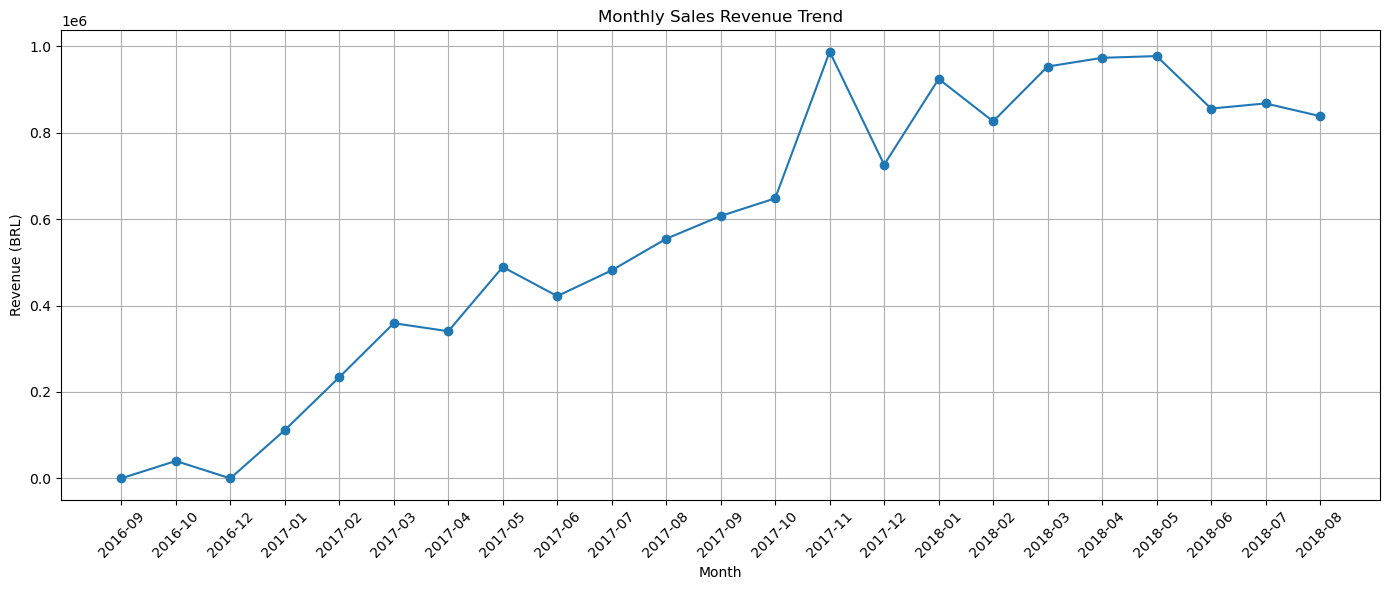

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
category_revenue = (
    sales_data.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_revenue.columns = [
    "Category",
    "Revenue"
]

display(category_revenue.head(10))

,Category,Revenue
0,health_beauty,1233131.72
1,watches_gifts,1166176.98
2,bed_bath_table,1023434.76
3,sports_leisure,954852.55
4,computers_accessories,888724.61
5,furniture_decor,711927.69
6,housewares,615628.69
7,cool_stuff,610204.10
8,auto,578966.65
9,toys,471286.48


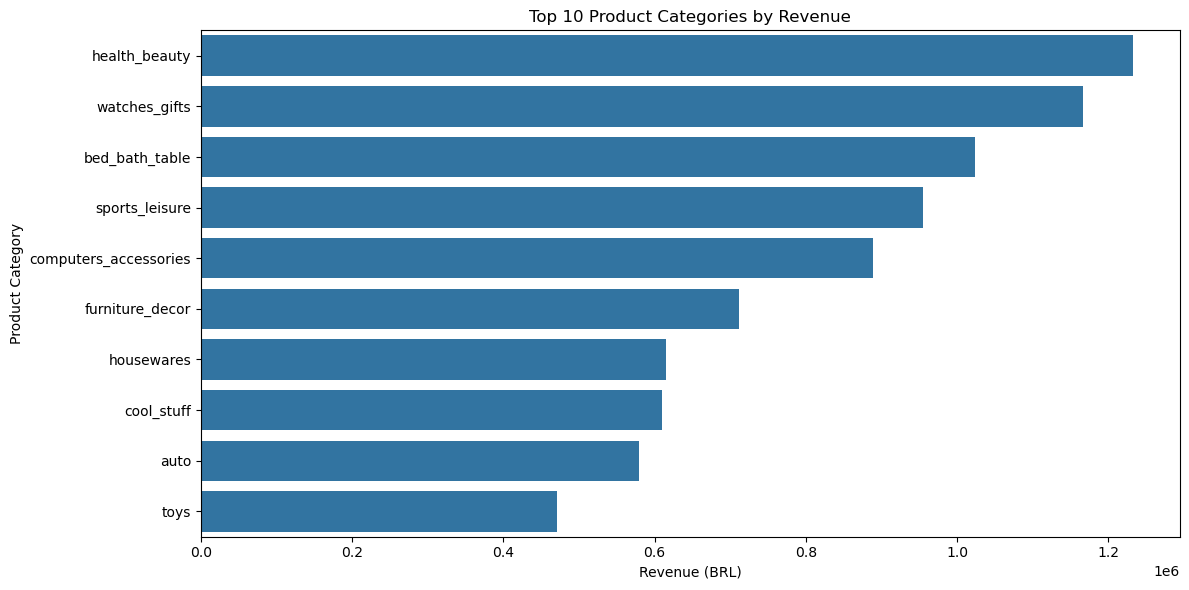

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_revenue.head(10),
    x="Revenue",
    y="Category"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [24]:
customer_sales = sales_data.merge(
    customers[
        ["customer_id", "customer_city", "customer_state",
         "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

display(customer_sales.head())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,product_photos_qty_missing,product_weight_g_missing,product_length_cm_missing,product_height_cm_missing,product_width_cm_missing,product_category_name_english,month,customer_city,customer_state,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,0,0,0,0,0,cool_stuff,2017-09,campos dos goytacazes,RJ,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,0,0,0,0,0,pet_shop,2017-04,santa fe do sul,SP,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,0,0,0,0,0,furniture_decor,2018-01,para de minas,MG,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,0,0,0,0,0,perfumery,2018-08,atibaia,SP,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,0,0,0,0,0,garden_tools,2017-02,varzea paulista,SP,64b576fb70d441e8f1b2d7d446e483c5


In [25]:
state_sales = (
    customer_sales.groupby("customer_state")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

state_sales.columns = ["State", "Revenue"]

display(state_sales.head(10))

,State,Revenue
0,SP,5067633.16
1,RJ,1759651.13
2,MG,1552481.83
3,RS,728897.47
4,PR,666063.51
5,SC,507012.13
6,BA,493584.14
7,DF,296498.41
8,GO,282836.70
9,ES,268643.45


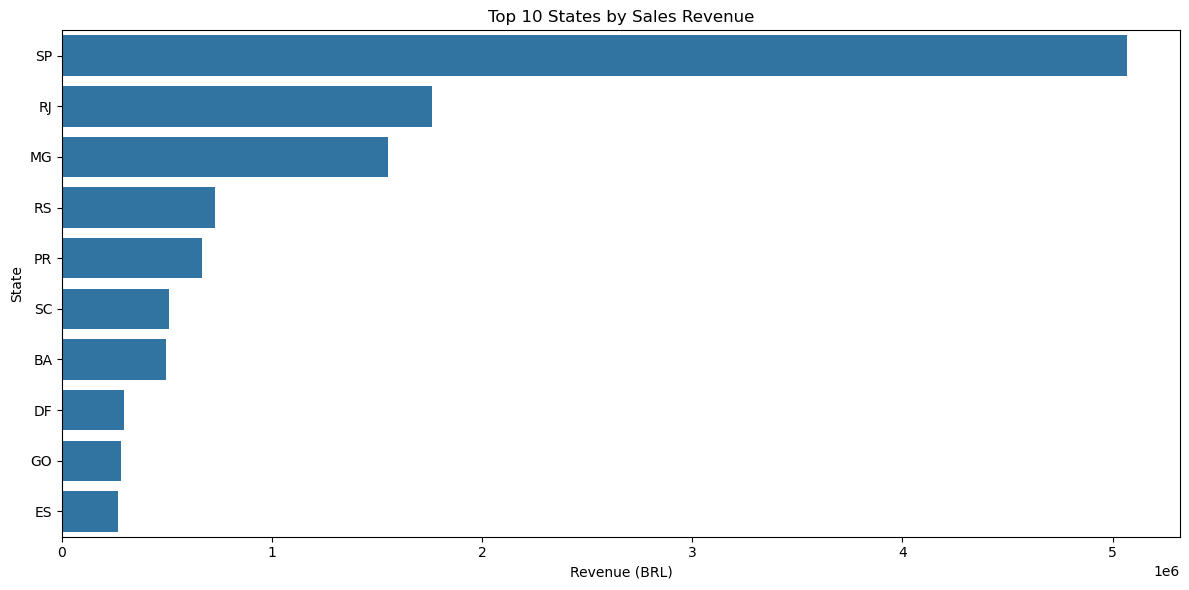

In [26]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=state_sales.head(10),
    x="Revenue",
    y="State"
)

plt.title("Top 10 States by Sales Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [27]:
total_customers = customer_sales["customer_unique_id"].nunique()

print("Total Unique Customers:", total_customers)

Total Unique Customers: 93358


In [28]:
customer_orders = (
    customer_sales.groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index()
)

customer_orders.columns = [
    "Customer ID",
    "Total Orders"
]

repeat_customers = customer_orders[
    customer_orders["Total Orders"] > 1
]

print("Repeat Customers:", len(repeat_customers))

print(
    "One-Time Customers:",
    len(customer_orders) - len(repeat_customers)
)

Repeat Customers: 2801
One-Time Customers: 90557


In [29]:
repeat_customer_percentage = (
    len(repeat_customers) / len(customer_orders)
) * 100

print(
    "Repeat Customer Percentage:",
    round(repeat_customer_percentage, 2),
    "%"
)

Repeat Customer Percentage: 3.0 %


In [30]:
purchase_distribution = (
    customer_orders["Total Orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

purchase_distribution.columns = [
    "Number of Orders",
    "Number of Customers"
]

display(purchase_distribution.head(10))

,Number of Orders,Number of Customers
0,1,90557
1,2,2573
2,3,181
3,4,28
4,5,9
5,6,5
6,7,3
7,9,1
8,15,1


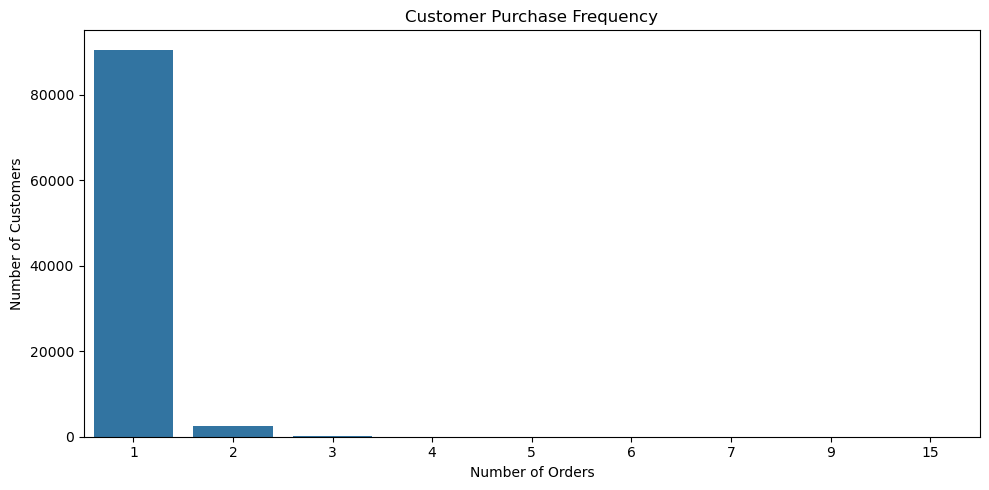

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=purchase_distribution.head(10),
    x="Number of Orders",
    y="Number of Customers"
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [32]:
payment_analysis = (
    payments.groupby("payment_type")["payment_value"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

payment_analysis.columns = [
    "Payment Method",
    "Total Payment"
]

display(payment_analysis)

,Payment Method,Total Payment
0,credit_card,12542084.19
1,boleto,2869361.27
2,voucher,379436.87
3,debit_card,217989.79
4,not_defined,0.00


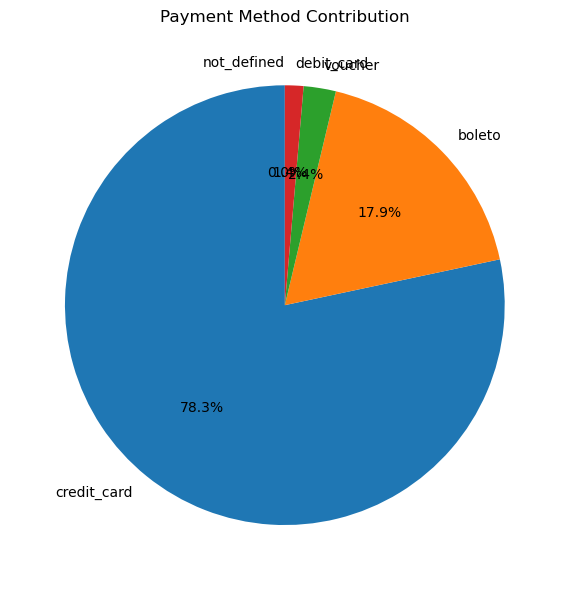

In [33]:
plt.figure(figsize=(8, 6))

plt.pie(
    payment_analysis["Total Payment"],
    labels=payment_analysis["Payment Method"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Contribution")

plt.tight_layout()
plt.show()

In [34]:
print("========== BUSINESS INSIGHTS ==========")

print(
    "\n1. Highest Revenue Month:",
    monthly_sales.loc[
        monthly_sales["Revenue"].idxmax(), "Month"
    ]
)

print(
    "\n2. Highest Revenue Category:",
    category_revenue.iloc[0]["Category"]
)

print(
    "\n3. Highest Revenue State:",
    state_sales.iloc[0]["State"]
)

print(
    "\n4. Total Unique Customers:",
    total_customers
)

print(
    "\n5. Repeat Customer Percentage:",
    round(repeat_customer_percentage, 2), "%"
)

print(
    "\n6. Most Used Payment Method:",
    payments["payment_type"].mode()[0]
)

print(
    "\n7. Total Delivered Sales Revenue:",
    round(total_revenue, 2)
)

========== BUSINESS INSIGHTS ==========

1. Highest Revenue Month: 2017-11

2. Highest Revenue Category: health_beauty

3. Highest Revenue State: SP

4. Total Unique Customers: 93358

5. Repeat Customer Percentage: 3.0 %

6. Most Used Payment Method: credit_card

7. Total Delivered Sales Revenue: 13221498.11


In [35]:
monthly_sales.to_csv(
    REPORT_PATH / "monthly_sales_trend.csv",
    index=False
)

In [36]:
category_revenue.to_csv(
    REPORT_PATH / "category_revenue.csv",
    index=False
)

In [37]:
state_sales.to_csv(
    REPORT_PATH / "state_sales.csv",
    index=False
)

In [38]:
customer_orders.to_csv(
    REPORT_PATH / "customer_purchase_analysis.csv",
    index=False
)

In [39]:
payment_analysis.to_csv(
    REPORT_PATH / "payment_analysis.csv",
    index=False
)

print("All Task 2 analysis reports saved successfully!")

All Task 2 analysis reports saved successfully!
